# IS6400 Week 7: credit-card classification

LI Binxiong · 60234350

The course tutorial is followed by my answers to Questions 1–3. Class 1 is the positive class in the assignment analysis.

In [1]:
from pathlib import Path
import os
from IPython.display import display, HTML, Markdown
DATA = Path('data') if Path('data/creditcard-reduced.csv').is_file() else Path('.')
assert (DATA/'creditcard-reduced.csv').is_file() and (DATA/'Credit_approval.csv').is_file()
os.chdir(DATA)
display(HTML("<style>.jp-Notebook{max-width:1080px;margin:auto}.jp-RenderedHTMLCommon{font-size:18px;line-height:1.65}.jp-RenderedHTMLCommon table{font-size:16px}.jp-CodeCell .highlight pre{font-size:14px !important;line-height:1.5}.jp-RenderedImage img{max-width:100%;height:auto}</style>"))

# Classification - Ensemble Learning

The following tutorial contains Python examples for solving classification problems. You should refer to the Slides Week 7 to understand some of the concepts introduced in this tutorial. 

Classification is the task of predicting a nominal-valued attribute (known as class label) based on the values of other attributes (known as predictor variables). The goals for this tutorial are as follows:
1. To provide examples of using different ensemble learning techniques from the scikit-learn library package.
2. To make a model performance comparison.

Read the step-by-step instructions below carefully. To execute the code, click on the corresponding cell and press the SHIFT-ENTER keys simultaneously.


# Summary of toolbox

1. training testing data split. from sklearn.model_selection import train_test_split
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

2. decision tree. from sklearn.tree import DecisionTreeClassifier
https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

3. Random Forest. from sklearn.ensemble import RandomForestClassifier
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

4. Bagging. from sklearn.ensemble import BaggingClassifier
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html

5. Adaboosting. from sklearn.ensemble import AdaBoostClassifier
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html

6. StackingClassifier. from sklearn.ensemble import StackingClassifier
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html

7. confusion matrix. from sklearn.metrics import ConfusionMatrixDisplay
https://scikit-learn.org/stable/auto_examples/model_selection/plot_confusion_matrix.html
    
8. weighted classification. 
weights = {0:10.0, 1:1.0} #the weight put the weight for class "0" to 10 and "1" to 1. So the "0" class is more important
clf = DecisionTreeClassifier(max_depth=2,class_weight=weights)
    

## Hold-out Data preparation

In [2]:
from sklearn.model_selection import train_test_split # this function provides a single "Hold-Out" Validation.
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score #similar to MAE, we use accuracy_score evaluation metric.
import pandas as pd
import numpy as np

data = pd.read_csv('Credit_approval.csv',header='infer')
data.head(5)

,Age,Debt,YearsEmployed,CreditScore,Income,Approved
0,30.83,0.000,1.25,1,0,+
1,58.67,4.460,3.04,6,560,+
2,24.50,0.500,1.50,0,824,+
3,27.83,1.540,3.75,5,3,+
4,20.17,5.625,1.71,0,0,+


In [3]:
Y = data['Approved'] #this is our prediction target
X = data.drop(['Approved'],axis=1)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.4, random_state=1) 
# From original dataset, 0.4 (40%) is used for testing (validation). random_state ensures random split is fixed.

# <span style="background-color: yellow;">Base Classifiers</span> 
## 1. Decision Tree Classifier

In [4]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(max_depth=2) # number estimators is the key parameter
clf = clf.fit(X_train, Y_train)
Y_predTrain = clf.predict(X_train)
Y_predTest = clf.predict(X_test)

print('Training accuracy is %f' % accuracy_score(Y_train, Y_predTrain))
      
print('Validation accuracy is %f' %accuracy_score(Y_test, Y_predTest))

Training accuracy is 0.751232
Validation accuracy is 0.727941


# <span style="background-color: yellow;">Ensemble Classifiers</span> 
## 1. Random Forest 

In [5]:
from sklearn.ensemble import RandomForestClassifier
np.random.seed(1) #because the model has random sampling, a random seed can ensure repeated results.
clf = RandomForestClassifier(max_depth=2,n_estimators=500)
clf = clf.fit(X_train, Y_train)
Y_predTrain = clf.predict(X_train)
Y_predTest = clf.predict(X_test)

print('Training accuracy is %f' % accuracy_score(Y_train, Y_predTrain))
      
print('Validation accuracy is %f' %accuracy_score(Y_test, Y_predTest))

Training accuracy is 0.780788
Validation accuracy is 0.761029


## 2. Bagging

In [6]:
from sklearn.ensemble import BaggingClassifier
np.random.seed(1)
clf2 = BaggingClassifier(DecisionTreeClassifier(max_depth=2),n_estimators=50) # number estimators is the key parameter
clf2 = clf2.fit(X_train, Y_train)
Y_predTrain = clf2.predict(X_train)
Y_predTest = clf2.predict(X_test)

print('Training accuracy is %f' % accuracy_score(Y_train, Y_predTrain))
      
print('Validation accuracy is %f' %accuracy_score(Y_test, Y_predTest))

Training accuracy is 0.778325
Validation accuracy is 0.735294


## 3. AdaBoost

In [7]:
from sklearn.ensemble import AdaBoostClassifier
np.random.seed(1)
clf3 = AdaBoostClassifier(DecisionTreeClassifier(max_depth=2),n_estimators=5) # number estimators is the key parameter
clf3 = clf3.fit(X_train, Y_train)
Y_predTrain = clf3.predict(X_train)
Y_predTest = clf3.predict(X_test)

print('Training accuracy is %f' % accuracy_score(Y_train, Y_predTrain))
      
print('Validation accuracy is %f' %accuracy_score(Y_test, Y_predTest))

Training accuracy is 0.805419
Validation accuracy is 0.779412


D:\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


## 4. StackingClassifier

In [8]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import numpy as np

np.random.seed(1)

# ---- level-1 base estimators ----
base_estimators = [
    ("dt",  DecisionTreeClassifier(max_depth=3, random_state=1)),
    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))),
    ("svm", make_pipeline(StandardScaler(), SVC(probability=True, C=1.0, kernel="rbf", random_state=1))),
]

# ---- level-2 meta estimator ----
meta_estimator = LogisticRegression(max_iter=2000, random_state=1)

clf_stack = StackingClassifier(
    estimators=base_estimators,
    final_estimator=meta_estimator,
    cv=5,                # fold number
    stack_method="auto", # automatically select predict_proba / decision_function
    passthrough=False    # pass original features to level 2, can be set as True
)

# training
clf_stack.fit(X_train, Y_train)

# prediction
Y_predTrain = clf_stack.predict(X_train)
Y_predTest  = clf_stack.predict(X_test)

print('Training accuracy is %f'   % accuracy_score(Y_train, Y_predTrain))
print('Validation accuracy is %f' % accuracy_score(Y_test,  Y_predTest))

Training accuracy is 0.805419
Validation accuracy is 0.764706


# <span style="background-color: pink;">Model Comparision</span> 

[[ 70  47]
 [ 18 137]]


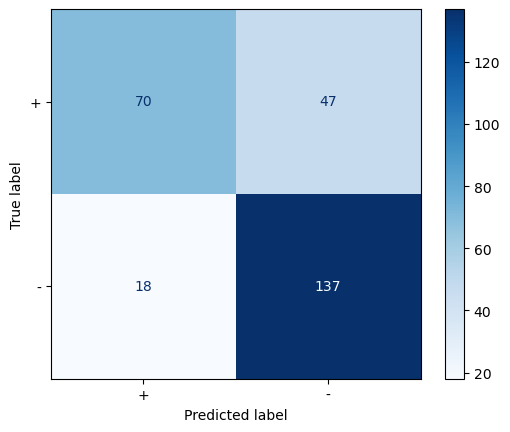

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, Y_test,display_labels=['+','-'],values_format = '.0f',cmap=plt.cm.Blues)
np.set_printoptions(precision=1)
print(disp.confusion_matrix)

# <span style="background-color: yellow;">Class-weight method for imbalanced classification</span> 

Counter({1: 9000, 0: 1000})


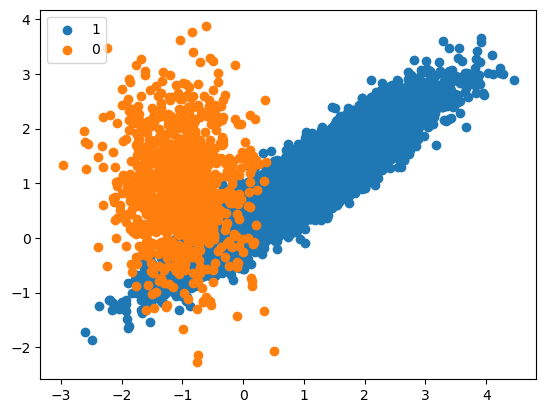

In [10]:
from sklearn.datasets import make_classification
from matplotlib import pyplot
from numpy import where
# Generate and plot a synthetic imbalanced classification dataset
from collections import Counter
# define dataset
np.random.seed(1)
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
                           n_clusters_per_class=1, weights=[0.1], flip_y=0, random_state=2) 
#randomly generate an imbalanced 2-dimensional binary set

counter = Counter(y)
print(counter) #count how many 1 and how many 0

for label, _ in counter.items():
    row_ix = where(y == label)[0]
    pyplot.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
pyplot.legend()
pyplot.show()

X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.4, random_state=1) 

[[ 262  124]
 [   8 3606]]


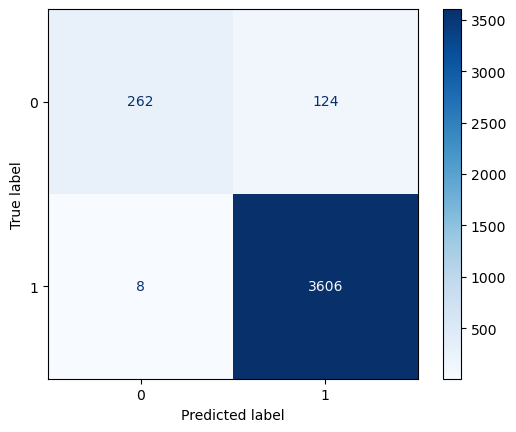

In [11]:
clf=DecisionTreeClassifier(max_depth=2)
clf = clf.fit(X_train, Y_train)
Y_predTrain = clf.predict(X_train)
Y_predTest = clf.predict(X_test)
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, Y_test,display_labels=['0','1'],values_format = '.0f',cmap=plt.cm.Blues)
np.set_printoptions(precision=1)
print(disp.confusion_matrix) #direct implementation. the number of 0 labels that were misclassified as 1 is high

[[ 376   10]
 [ 532 3082]]


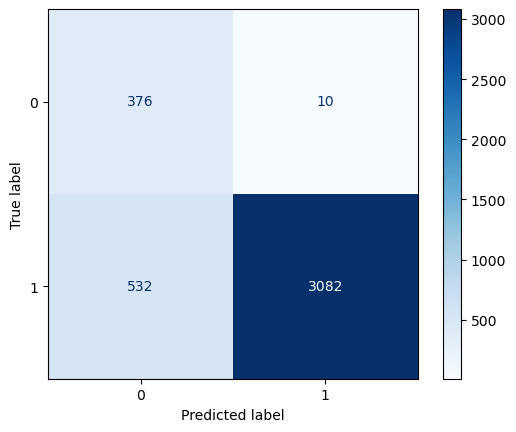

In [12]:
weights = {0:10.0, 1:1.0} #the weight put the weight for class "0" to 10 and "1" to 1. So the "0" class is more important
clf = DecisionTreeClassifier(max_depth=2,class_weight=weights)
clf = clf.fit(X_train, Y_train)
Y_predTrain = clf.predict(X_train)
Y_predTest = clf.predict(X_test)
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, Y_test,display_labels=['0','1'],values_format = '.0f',cmap=plt.cm.Blues)
np.set_printoptions(precision=1)
print(disp.confusion_matrix)

## Summary

### 1. Learn how to build Ensemble Learning Methods
### 2. Learn how to import different classfiers. Please go to the Sklearn website for more details if you want to study more. https://scikit-learn.org/stable/auto_examples/index.html#classification
### 3. Learn how to compute the confusion matrix
### 4. Learn how to compute the class-sensitive classification

# Week 7 Assignment

### 1.  Use the credictcard-reduced.csv dataset and build Five classification models. Please plot confusion matrix, and evaluate your model performance using accuracy, precision, recall, F-score (50 points). A list of classification models can be found [here](https://scikit-learn.org/stable/auto_examples/classification/plot_classifier_comparison.html)

### 2.  Illustrate the differences between these classifiers and compare the model performances. (30 points)

### 3.  Use the class-weight method from the tutorial for imbalanced classification on the creditcard-reduced.csv dataset. Build a classifier with and without class_weight, then evaluate model performance before and after applying class weights using accuracy, precision, recall, F-score, and confusion matrix.(20 points)

# Q1. Five classifiers and their performance

## Data and comparison setup

I use `creditcard-reduced.csv`, with `Class` as the target and the other 30 columns as predictors. Class 1 is the minority class. I remove records that match in all columns before splitting, then use a stratified 60% training / 40% test split with `random_state=42`.

All five classifiers use the same training rows, test rows and predictors. Logistic regression uses a scaler fitted within its training pipeline. The tree models use the supplied numeric features directly.

In [13]:
import sys, json, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

raw = pd.read_csv('creditcard-reduced.csv')
data = raw.drop_duplicates().copy()
assert data.notna().all().all() and np.isfinite(data.to_numpy()).all()
assert set(data['Class']) == {0,1}
X = data.drop(columns='Class')
y = data['Class'].astype(int)
train_index, test_index = train_test_split(data.index, test_size=0.4, stratify=y, random_state=42)
X_train, X_test = X.loc[train_index], X.loc[test_index]
y_train, y_test = y.loc[train_index], y.loc[test_index]
assert set(train_index).isdisjoint(test_index)
assert set(pd.util.hash_pandas_object(data.loc[train_index], index=False)).isdisjoint(
       set(pd.util.hash_pandas_object(data.loc[test_index], index=False)))
print('Python',sys.version.split()[0],'; pandas',pd.__version__,'; scikit-learn',sklearn.__version__)
print('Original rows:',len(raw),'; identical records removed:',len(raw)-len(data),'; retained:',len(data))
print('Predictors:',X.shape[1],'; missing cells:',int(raw.isna().sum().sum()))
class_counts = pd.DataFrame({'All':y.value_counts(),'Train':y_train.value_counts(),'Test':y_test.value_counts()}).sort_index()
class_counts.index.name='Class'
display(class_counts)
print(f'Positive-class share: {y.mean():.6%}')

Python 3.12.3 ; pandas 2.3.3 ; scikit-learn 1.5.1
Original rows: 32764 ; identical records removed: 177 ; retained: 32587
Predictors: 30 ; missing cells: 0


,All,Train,Test
Class,,,
0,32114,19268,12846
1,473,284,189


Positive-class share: 1.451499%


## Metrics

The confusion matrices use actual classes as rows and predicted classes as columns, in the order 0, 1. A true positive (TP) is a class-1 record predicted as 1. A false negative (FN) is a class-1 record predicted as 0. False positives (FP) are class-0 records predicted as 1; true negatives (TN) are class-0 records predicted as 0.

I report accuracy and the class-1 precision, recall and F1-score:

$$
\mathrm{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\qquad
\mathrm{Precision}=\frac{TP}{TP+FP}.
$$

$$
\mathrm{Recall}=\frac{TP}{TP+FN},\qquad
F_1=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}.
$$

For example, TP=8, FP=2 and FN=4 give precision $8/10=0.8$, recall $8/12\approx0.666667$ and F1 $16/22\approx0.727273$. Accuracy counts all correct predictions; precision and recall describe different errors on the positive class.

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic regression,0.999386,0.989189,0.968254,0.978610
Decision tree,0.999540,0.974093,0.994709,0.984293
Random forest,0.999540,0.984127,0.984127,0.984127
Bagging,0.999616,0.979167,0.994709,0.986877
AdaBoost,0.999770,0.989474,0.994709,0.992084


,TN,FP,FN,TP
Model,,,,
Logistic regression,12844,2,6,183
Decision tree,12841,5,1,188
Random forest,12843,3,3,186
Bagging,12842,4,1,188
AdaBoost,12844,2,1,188


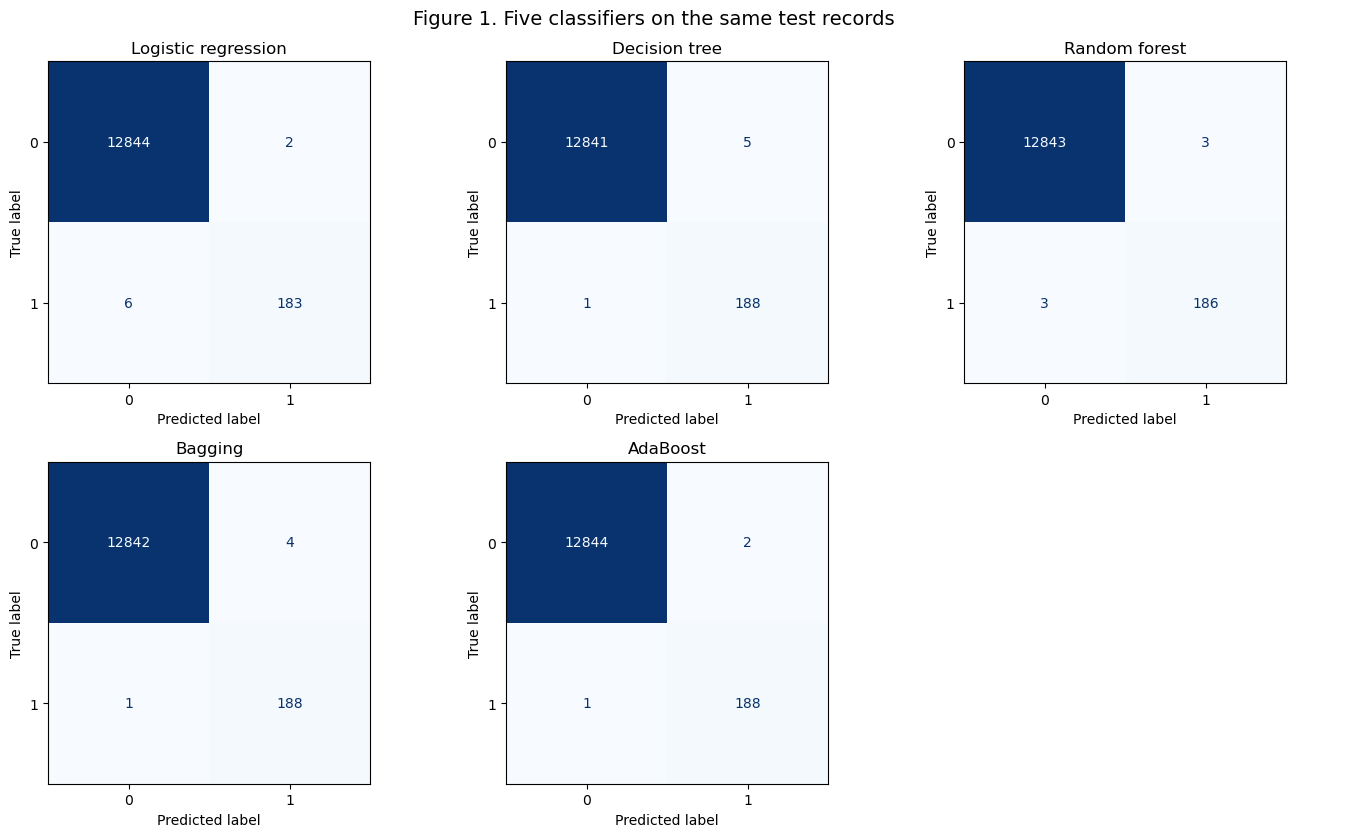

In [14]:
models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42)),
    'Decision tree': DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=42),
    'Random forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1),
    'Bagging': BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=5, min_samples_leaf=5),
                                 n_estimators=100, random_state=42, n_jobs=-1),
    'AdaBoost': AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2, min_samples_leaf=5),
                                    n_estimators=100, learning_rate=0.5, algorithm='SAMME', random_state=42),
}
predictions = {}
matrices = {}
score_rows = []
fit_warnings = {}
for name, model in models.items():
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        model.fit(X_train, y_train)
    fit_warnings[name] = [str(w.message) for w in captured]
    prediction = model.predict(X_test)
    predictions[name] = prediction
    matrix = confusion_matrix(y_test,prediction,labels=[0,1])
    matrices[name] = matrix
    tn,fp,fn,tp = matrix.ravel()
    assert int(tn+fp+fn+tp)==len(y_test)
    score_rows.append({'Model':name,'Accuracy':accuracy_score(y_test,prediction),
                       'Precision':precision_score(y_test,prediction,zero_division=0),
                       'Recall':recall_score(y_test,prediction,zero_division=0),
                       'F1':f1_score(y_test,prediction,zero_division=0),
                       'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)})
scores = pd.DataFrame(score_rows).set_index('Model')
display(scores[['Accuracy','Precision','Recall','F1']].style.format('{:.6f}'))
display(scores[['TN','FP','FN','TP']])
for name, messages in fit_warnings.items():
    for message in messages:print(name+': '+message)
fig, axes = plt.subplots(2,3,figsize=(14,8.5))
for ax,(name,matrix) in zip(axes.flat,matrices.items()):
    ConfusionMatrixDisplay(matrix,display_labels=['0','1']).plot(ax=ax,cmap='Blues',colorbar=False,
          values_format='d',im_kw={'vmin':0,'vmax':len(y_test)})
    ax.set_title(name,fontsize=12)
axes.flat[-1].axis('off')
fig.suptitle('Figure 1. Five classifiers on the same test records',fontsize=14)
fig.tight_layout();fig.savefig('week7-five-matrices.svg');plt.show()

# Q2. Differences between the classifiers

Logistic regression fits a linear boundary after scaling the inputs. The decision tree splits individual features into regions; I limit it to depth 5 with at least 5 training records per leaf. Random forest averages 200 trees fitted with bootstrap samples and random feature subsets. Bagging averages 100 depth-5 trees fitted to bootstrap samples. AdaBoost fits 100 small depth-2 trees sequentially, giving more influence to previously misclassified training records; I use SAMME with a learning rate of 0.5.

The models therefore differ in the boundaries they can fit and how they combine trees. A single tree is easy to follow but depends on its chosen splits. Forest and bagging average several fitted trees. AdaBoost adjusts the training emphasis at each stage, while logistic regression estimates one set of coefficients.

In [15]:
majority_prediction = np.zeros(len(y_test),dtype=int)
majority_accuracy = accuracy_score(y_test,majority_prediction)
best_f1_name = scores['F1'].idxmax()
recall_leaders = ', '.join(scores.index[scores['Recall'].eq(scores['Recall'].max())])
best_precision_name = scores['Precision'].idxmax()
best_f1 = scores.loc[best_f1_name]
display(Markdown(
    f"{best_f1_name} has the highest test F1-score, {best_f1['F1']:.6f}, "
    f"with precision {best_f1['Precision']:.6f} and recall {best_f1['Recall']:.6f}. "
    f"It detects {int(best_f1['TP'])} of the {int(y_test.sum())} positive records and produces "
    f"{int(best_f1['FP'])} false positives. "
    f"The highest recall, {scores['Recall'].max():.6f}, is shared by {recall_leaders}; "
    f"while {best_precision_name} has the highest precision ({scores.loc[best_precision_name,'Precision']:.6f})."
))
display(Markdown(
    f"Predicting every record as class 0 gives accuracy {majority_accuracy:.6f}, "
    "but recall and F1 are both 0.000000 because every positive record is missed. "
    "The confusion matrices and positive-class metrics are therefore more informative than accuracy alone. "
    f"For a balance between positive detections and false alarms in this comparison, I would choose {best_f1_name}."
))

AdaBoost has the highest test F1-score, 0.992084, with precision 0.989474 and recall 0.994709. It detects 188 of the 189 positive records and produces 2 false positives. The highest recall, 0.994709, is shared by Decision tree, Bagging, AdaBoost; while AdaBoost has the highest precision (0.989474).

Predicting every record as class 0 gives accuracy 0.985501, but recall and F1 are both 0.000000 because every positive record is missed. The confusion matrices and positive-class metrics are therefore more informative than accuracy alone. For a balance between positive detections and false alarms in this comparison, I would choose AdaBoost.

# Q3. Classification with and without class weights

I compare two depth-5 decision trees with the same minimum leaf size, random seed, predictors and data split. The second tree gives class 1 more weight. I calculate the weight from training counts:

$$
w_0=1,\qquad w_1=\frac{n_0}{n_1},
$$

where $n_0$ and $n_1$ count the class-0 and class-1 training records. This gives the two classes equal total weight when choosing splits. The weights change the fitting criterion rather than adding records or changing their labels.

Training class weights: class 0 = 1.000000; class 1 = 67.845070


,Accuracy,Precision,Recall,F1
Model,,,,
Without class weights,0.999540,0.974093,0.994709,0.984293
With class weights,0.999386,0.964103,0.994709,0.979167


,TN,FP,FN,TP
Model,,,,
Without class weights,12841,5,1,188
With class weights,12839,7,1,188


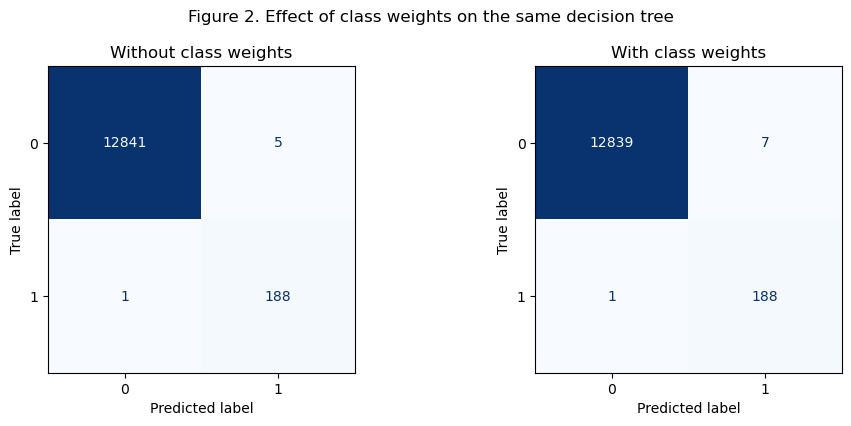

In [16]:
training_counts = y_train.value_counts()
class_weights = {0:1.0,1:float(training_counts[0]/training_counts[1])}
weight_models = {
    'Without class weights': DecisionTreeClassifier(max_depth=5,min_samples_leaf=5,random_state=42),
    'With class weights': DecisionTreeClassifier(max_depth=5,min_samples_leaf=5,random_state=42,
                                               class_weight=class_weights),
}
weight_rows=[]
weight_matrices={}
for name,model in weight_models.items():
    model.fit(X_train,y_train)
    prediction=model.predict(X_test)
    matrix=confusion_matrix(y_test,prediction,labels=[0,1])
    weight_matrices[name]=matrix
    tn,fp,fn,tp=matrix.ravel()
    weight_rows.append({'Model':name,'Accuracy':accuracy_score(y_test,prediction),
                       'Precision':precision_score(y_test,prediction,zero_division=0),
                       'Recall':recall_score(y_test,prediction,zero_division=0),
                       'F1':f1_score(y_test,prediction,zero_division=0),
                       'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)})
weighted_scores=pd.DataFrame(weight_rows).set_index('Model')
print(f'Training class weights: class 0 = {class_weights[0]:.6f}; class 1 = {class_weights[1]:.6f}')
display(weighted_scores[['Accuracy','Precision','Recall','F1']].style.format('{:.6f}'))
display(weighted_scores[['TN','FP','FN','TP']])
assert np.array_equal(weight_matrices['Without class weights'],matrices['Decision tree'])
fig,axes=plt.subplots(1,2,figsize=(10,4.3))
for ax,(name,matrix) in zip(axes,weight_matrices.items()):
    ConfusionMatrixDisplay(matrix,display_labels=['0','1']).plot(ax=ax,cmap='Blues',colorbar=False,
              values_format='d',im_kw={'vmin':0,'vmax':len(y_test)})
    ax.set_title(name)
fig.suptitle('Figure 2. Effect of class weights on the same decision tree')
fig.tight_layout();fig.savefig('week7-weighted-matrices.svg');plt.show()

In [17]:
unweighted=weighted_scores.loc['Without class weights']
weighted=weighted_scores.loc['With class weights']
display(Markdown(
    f"Both trees detect {int(weighted['TP'])} of the {int(y_test.sum())} positive records, "
    f"giving recall {weighted['Recall']:.6f}. Weighting changes precision from "
    f"{unweighted['Precision']:.6f} to {weighted['Precision']:.6f}, "
    f"and F1 from {unweighted['F1']:.6f} to {weighted['F1']:.6f}. "
    f"False positives increase from {int(unweighted['FP'])} to {int(weighted['FP'])}, "
    f"while each tree misses {int(weighted['FN'])} positive record. "
    "The higher class-1 training weight changes which splits the tree selects."
))

Both trees detect 188 of the 189 positive records, giving recall 0.994709. Weighting changes precision from 0.974093 to 0.964103, and F1 from 0.984293 to 0.979167. False positives increase from 5 to 7, while each tree misses 1 positive record. The higher class-1 training weight changes which splits the tree selects.

## Additional analysis: the cost of the two error types

The preferred class-weight setting depends on the relative cost of a false positive and a missed positive. To compare the observed counts, let one false positive cost one unit and one false negative cost $r$ units:

$$
\mathrm{Cost}(r)=FP+r\,FN.
$$

The table uses assumed ratios $r=1,10,50,100$; these are scenarios, not measured business costs. For example, FP=10 and FN=3 give $10+10\times3=40$ units when $r=10$.

In [18]:
cost_rows=[]
for ratio in [1,10,50,100]:
    cost_rows.append({'FN/FP cost ratio':ratio,
                     'Without weights':int(unweighted['FP']+ratio*unweighted['FN']),
                     'With weights':int(weighted['FP']+ratio*weighted['FN'])})
costs=pd.DataFrame(cost_rows)
display(costs.style.hide(axis='index'))
fn_reduction=float(unweighted['FN']-weighted['FN'])
fp_increase=float(weighted['FP']-unweighted['FP'])
if fn_reduction>0:
    break_even=fp_increase/fn_reduction
    display(Markdown(
        f"The weighted tree prevents {int(fn_reduction)} missed positives and changes false positives by "
        f"{int(fp_increase)}. Its lower error cost begins when a missed positive costs more than "
        f"{break_even:.6f} times a false positive. "
        "This separates the effect on recall from the choice of which error is more costly. "
        "The scores above describe a stratified random hold-out from the supplied file."
    ))
else:
    display(Markdown(
        f"Both trees miss {int(unweighted['FN'])} positive record. Weighting increases false positives "
        f"from {int(unweighted['FP'])} to {int(weighted['FP'])}, so its error cost is "
        f"{int(fp_increase)} units higher at every listed ratio. I would keep the unweighted tree for this split."
    ))
results={'original_rows':len(raw),'removed_duplicates':len(raw)-len(data),'rows':len(data),
         'predictors':X.shape[1],'seed':42,'test_fraction':0.4,
         'class_counts':class_counts.to_dict(),'models':scores.reset_index().to_dict(orient='records'),
         'weights':class_weights,'weighted_models':weighted_scores.reset_index().to_dict(orient='records'),
         'costs':cost_rows,'fit_warnings':fit_warnings,'majority_accuracy':float(majority_accuracy)}
_ = Path('week7-results.json').write_text(json.dumps(results,indent=2),encoding='utf-8')

FN/FP cost ratio,Without weights,With weights
1,6,8
10,15,17
50,55,57
100,105,107


Both trees miss 1 positive record. Weighting increases false positives from 5 to 7, so its error cost is 2 units higher at every listed ratio. I would keep the unweighted tree for this split.

## Training-data check: the role of Time

The training classes occupy different ranges of `Time`. I examine this using a separate stratified 70%/30% split of the training rows and a fixed depth-5 tree using only `Time`. This check leaves the outer test set and the five-model comparison unchanged.

In [19]:
time_ranges = data.loc[train_index].groupby('Class')['Time'].agg(['min','max','median','count'])
display(time_ranges.style.format({'median':'{:.6f}'}))
inner_fit_index, inner_validation_index = train_test_split(train_index,test_size=0.3,
                            stratify=y_train,random_state=42)
time_only = DecisionTreeClassifier(max_depth=5,min_samples_leaf=5,random_state=42)
time_only.fit(X.loc[inner_fit_index,['Time']],y.loc[inner_fit_index])
time_prediction = time_only.predict(X.loc[inner_validation_index,['Time']])
time_f1 = f1_score(y.loc[inner_validation_index],time_prediction,zero_division=0)
time_matrix = confusion_matrix(y.loc[inner_validation_index],time_prediction,labels=[0,1])
time_importance = float(models['Decision tree'].feature_importances_[X.columns.get_loc('Time')])
print('Internal validation confusion matrix (Time only):')
print(time_matrix)
print(f'Internal validation F1 (Time only): {time_f1:.6f}')
print(f'Fitted Q1 tree importance assigned to Time: {time_importance:.6f}')
display(Markdown(
    f"Class 0 training records have Time values from {int(time_ranges.loc[0,'min'])} to "
    f"{int(time_ranges.loc[0,'max'])}, while class 1 ranges from {int(time_ranges.loc[1,'min'])} to "
    f"{int(time_ranges.loc[1,'max'])}. A tree using Time alone reaches internal validation F1 "
    f"{time_f1:.6f}. Time also accounts for {time_importance:.6%} of the Q1 tree's fitted impurity reduction. "
    "The high random-split scores partly reflect this strong class separation within the supplied sample. "
    "They should be read as a comparison on that sample rather than as a forecast of later records."
))
results['time_audit']={'training_ranges':time_ranges.to_dict(),'internal_validation_F1':float(time_f1),
                       'internal_validation_matrix':time_matrix.tolist(),'tree_importance':time_importance}
_ = Path('week7-results.json').write_text(json.dumps(results,indent=2),encoding='utf-8')

,min,max,median,count
Class,,,,
0,155839,172792,163279.500000,19268
1,406,170348,70249.500000,284


Internal validation confusion matrix (Time only):
[[5781    0]
 [   7   78]]
Internal validation F1 (Time only): 0.957055
Fitted Q1 tree importance assigned to Time: 0.954175


Class 0 training records have Time values from 155839 to 172792, while class 1 ranges from 406 to 170348. A tree using Time alone reaches internal validation F1 0.957055. Time also accounts for 95.417488% of the Q1 tree's fitted impurity reduction. The high random-split scores partly reflect this strong class separation within the supplied sample. They should be read as a comparison on that sample rather than as a forecast of later records.

## Sources

IS6400, “Week 7 Classification_Tutorial.ipynb,” assignment Questions 1–3; supplied `creditcard-reduced.csv`. The model implementations are from scikit-learn; their settings are shown in the code.

I used OpenAI Codex to assist with this assignment.